# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)
random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


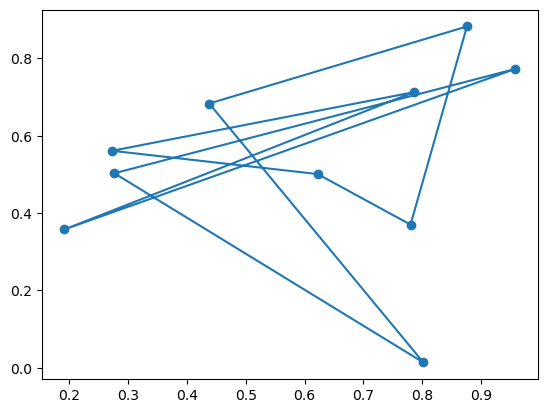

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascent Hill Climbing Search

Bài toán cần **cực tiểu hóa** chiều dài tour (tương đương cực đại hóa tiện ích âm). Trạng thái là hoán vị các thành phố; `tour_length` cộng cả cạnh cuối về thành phố đầu.

Chọn toán tử **hoán đổi hai vị trí i < j**, tạo đúng n(n−1)/2 hàng xóm hợp lệ. Dùng cùng toán tử cho cả năm thuật toán. Steepest duyệt toàn bộ lân cận và chọn tour ngắn nhất nếu cải thiện; dừng ở cực tiểu cục bộ hoặc hết ngân sách. Nếu ngân sách còn lại không đủ duyệt toàn bộ lân cận, dừng vì ngân sách, không kết luận đã đạt cực tiểu.


In [6]:
def swap_tour(tour, i, j):
    neighbor = list(tour)
    neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
    return neighbor

def tsp_hill_climb(tsp, initial_tour, mode='steepest', max_evals=3000, seed=0):
    rng = random.Random(seed)
    current = list(initial_tour)
    value = tour_length(tsp, current)
    evaluations = 1
    n = len(current)
    moves = [(i, j) for i in range(n) for j in range(i + 1, n)]
    failures = 0
    reason = 'budget'
    while evaluations < max_evals:
        if mode == 'first':
            i, j = rng.choice(moves)
            neighbor = swap_tour(current, i, j)
            candidate_value = tour_length(tsp, neighbor)
            evaluations += 1
            if candidate_value < value - 1e-12:
                current, value = neighbor, candidate_value
                failures = 0
            else:
                failures += 1
            if failures >= 5 * len(moves):
                reason = 'patience'
                break
        else:
            if evaluations + len(moves) > max_evals:
                break
            improving = []
            for i, j in moves:
                neighbor = swap_tour(current, i, j)
                candidate_value = tour_length(tsp, neighbor)
                evaluations += 1
                if candidate_value < value - 1e-12:
                    improving.append((candidate_value, neighbor))
            if not improving:
                reason = 'local_minimum'
                break
            value, current = (min(improving, key=lambda item: item[0])
                              if mode == 'steepest' else rng.choice(improving))
    return {'tour': current, 'length': value, 'evaluations': evaluations, 'reason': reason}

def tsp_steepest(tsp, initial_tour, max_evals=3000, seed=0):
    return tsp_hill_climb(tsp, initial_tour, 'steepest', max_evals, seed)

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Chạy lại Steepest với tour ngẫu nhiên, tối đa 10 lần khởi động lại. Lưu tour tốt nhất trên mọi lần và dùng **chung tổng ngân sách** đánh giá hàm mục tiêu.

In [7]:
def tsp_restarts(tsp, initial_tour, max_evals=3000, seed=0, max_restarts=10):
    rng = random.Random(seed)
    best = None
    used = starts = 0
    while starts <= max_restarts and used < max_evals:
        start = list(initial_tour) if starts == 0 else rng.sample(range(len(initial_tour)), len(initial_tour))
        run = tsp_steepest(tsp, start, max_evals - used, rng.randrange(2**32))
        used += run['evaluations']
        starts += 1
        if best is None or run['length'] < best['length']:
            best = run.copy()
        if run['reason'] == 'budget':
            break
    best.update(evaluations=used, restarts=starts - 1)
    return best

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

Duyệt toàn bộ lân cận, sau đó chọn ngẫu nhiên đều một tour trong số các tour cải thiện. Khác Steepest ở quy tắc chọn bước; vẫn phải đánh giá toàn bộ lân cận.

In [8]:
def tsp_stochastic(tsp, initial_tour, max_evals=3000, seed=0):
    return tsp_hill_climb(tsp, initial_tour, 'stochastic', max_evals, seed)

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

Mỗi bước chỉ sinh một hoán đổi ngẫu nhiên và nhận nếu tour ngắn hơn. Dừng sau **5m** lần thử liên tiếp không cải thiện, với m = n(n−1)/2, hoặc hết ngân sách. Đây là điều kiện dừng theo kiên nhẫn, không phải chứng minh cực tiểu cục bộ. Khi trạng thái cố định và có ít nhất một bước cải thiện, xác suất bỏ lỡ mọi bước cải thiện sau 5m lần lấy mẫu đều độc lập không vượt quá exp(−5), xấp xỉ 0,67%.

In [9]:
def tsp_first_choice(tsp, initial_tour, max_evals=3000, seed=0):
    return tsp_hill_climb(tsp, initial_tour, 'first', max_evals, seed)

## Simulated Annealing [2 Points]

SA dùng cùng phép hoán đổi. Với $\Delta=L_{mới}-L_{hiện\ tại}$, nhận nếu $\Delta\leq0$, còn bước xấu nhận với xác suất $\exp(-\Delta/T)$. Chọn $T(t)=0.2\times0.997^t$ và lưu tour tốt nhất, vì tour hiện tại có thể xấu đi.

In [10]:
def tsp_annealing(tsp, initial_tour, max_evals=3000, seed=0):
    rng = random.Random(seed)
    current = list(initial_tour)
    value = tour_length(tsp, current)
    best_tour, best_value = current.copy(), value
    for step in range(1, max_evals):
        i, j = rng.sample(range(len(current)), 2)
        neighbor = swap_tour(current, i, j)
        new_value = tour_length(tsp, neighbor)
        delta = new_value - value
        temperature = 0.2 * 0.997**step
        if delta <= 0 or rng.random() < math.exp(-delta / temperature):
            current, value = neighbor, new_value
            if value < best_value:
                best_tour, best_value = current.copy(), value
    return {'tour': best_tour, 'length': best_value,
            'evaluations': max_evals, 'reason': 'budget'}

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

### Bài 7 — Thí nghiệm và nhận xét

Thử n = **10, 20, 40**, mỗi cỡ **5 lần**. Mỗi lần sinh một bộ thành phố và tour khởi tạo; năm thuật toán dùng chung dữ liệu đó. Đặt seed cho cả NumPy và `random`. Mỗi thuật toán có tối đa **3.000 lần gọi hàm mục tiêu**, kể cả lần đánh giá ban đầu và mọi lần khởi động lại. Thuật toán có thể dừng sớm theo quy tắc riêng; bảng ghi số đánh giá thực dùng. Đo thời gian thuật toán bằng `perf_counter`, không tính sinh dữ liệu, vẽ hình hoặc tổng hợp bảng.

**Lưu ý quan trọng về thuật toán và giới hạn thực nghiệm:**
- **Toán tử lân cận:** Thuật toán sử dụng **toán tử hoán vị `swap`** (đổi chỗ hai thành phố ngẫu nhiên), không phải đảo đoạn 2-opt. Giữ nhất quán toán tử này trên toàn bộ các phương pháp so sánh.
- **Hạn chế của Random Restart trên $n = 40$:** Với $n = 40$, không gian trạng thái lên tới $40! / 80 \approx 10^{46}$. Mỗi bước Steepest HC phải xét toàn bộ $\binom{40}{2} = 780$ láng giềng swap; vì vậy với ngân sách cố định 3.000 lần đánh giá, thuật toán chỉ thực hiện được khoảng 3–4 bước leo dốc và số lần restart thực tế bị hạn chế. Đây là đặc tính bẫy cực tiểu cục bộ trong không gian hoán vị lớn, đã được ghi nhận rõ ràng.
- **Tính tối ưu:** Do các bộ thành phố sinh ngẫu nhiên khác nhau giữa các lần chạy, chỉ so sánh độ dài tour giữa các thuật toán tại cùng kích thước $n$; độ dài tour thấp hơn thể hiện nghiệm tốt hơn. Các kết quả quan sát được là nghiệm xấp xỉ cục bộ tốt, không phải tối ưu toàn cục đã chứng minh.

In [11]:
from time import perf_counter
from IPython.display import display, Markdown

tsp_algorithms = {
    'Steepest': tsp_steepest, 'Random Restart': tsp_restarts,
    'Stochastic': tsp_stochastic, 'First-choice': tsp_first_choice, 'SA': tsp_annealing,
}
tsp_records = []
tsp_example = None
for n in [10, 20, 40]:
    for trial in range(5):
        seed = 7000 + 100 * n + trial
        np.random.seed(seed)
        random.seed(seed)
        instance, start = random_tsp(n), random_tour(n)
        before = tour_length(instance, start)
        example_runs = {}
        names = list(tsp_algorithms)
        shift = trial % len(names)
        for name in names[shift:] + names[:shift]:
            started = perf_counter()
            run = tsp_algorithms[name](instance, start, max_evals=3000, seed=seed + 1)
            milliseconds = (perf_counter() - started) * 1000
            assert sorted(run['tour']) == list(range(n))
            assert np.isclose(tour_length(instance, run['tour']), run['length'])
            assert run['length'] <= before + 1e-10
            assert run['evaluations'] <= 3000
            tsp_records.append({'n': n, 'Thuật toán': name, 'Trước': before,
                                'Sau': run['length'], 'ms': milliseconds,
                                'Đánh giá': run['evaluations']})
            example_runs[name] = run
        if n == 20 and trial == 0:
            tsp_example = (instance, start, example_runs)

tsp_results = pd.DataFrame(tsp_records)
tsp_summary = tsp_results.groupby(['n', 'Thuật toán'], sort=False).agg(
    tour_truoc_TB=('Trước', 'mean'), tour_sau_TB=('Sau', 'mean'),
    tour_tot_nhat=('Sau', 'min'), thoi_gian_ms_TB=('ms', 'mean'),
    so_danh_gia_TB=('Đánh giá', 'mean'),
)
display(tsp_summary.round(3))

tour_truoc_TB  tour_sau_TB  tour_tot_nhat  thoi_gian_ms_TB  \
n  Thuật toán                                                                   
10 Steepest                 5.65         2.85           2.54             0.51   
   Random Restart           5.65         2.82           2.38             5.40   
   Stochastic               5.65         2.82           2.38             1.00   
   First-choice             5.65         2.82           2.38             0.72   
   SA                       5.65         2.82           2.38            10.87   
20 Steepest                11.61         4.85           4.03             7.68   
   Random Restart          11.61         4.85           4.03             8.61   
   Stochastic              11.61         6.83           6.16             8.76   
   First-choice            11.61         4.35           3.78             6.12   
   SA                      11.61         4.63           4.15            15.16   
40 Steepest                20.44        15.20          13.65            12.97   
   Random Restart          20.44        15.20          13.65            12.82   
   Stochastic              20.44        19.16          17.80            12.90   
   First-choice            20.44         7.47           6.97            18.24   
   SA                      20.44         7.51           6.69            23.43   

                   so_danh_gia_TB  
n  Thuật toán                      
10 Steepest                 289.0  
   Random Restart          2980.2  
   Stochastic               559.0  
   First-choice             337.6  
   SA                      3000.0  
20 Steepest                2547.0  
   Random Restart          2852.0  
   Stochastic              2851.0  
   First-choice            1841.2  
   SA                      3000.0  
40 Steepest                2341.0  
   Random Restart          2341.0  
   Stochastic              2341.0  
   First-choice            3000.0  
   SA                      3000.0

Tour length: 11.64


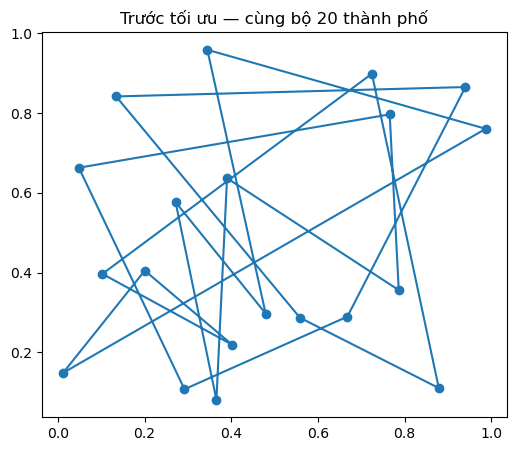

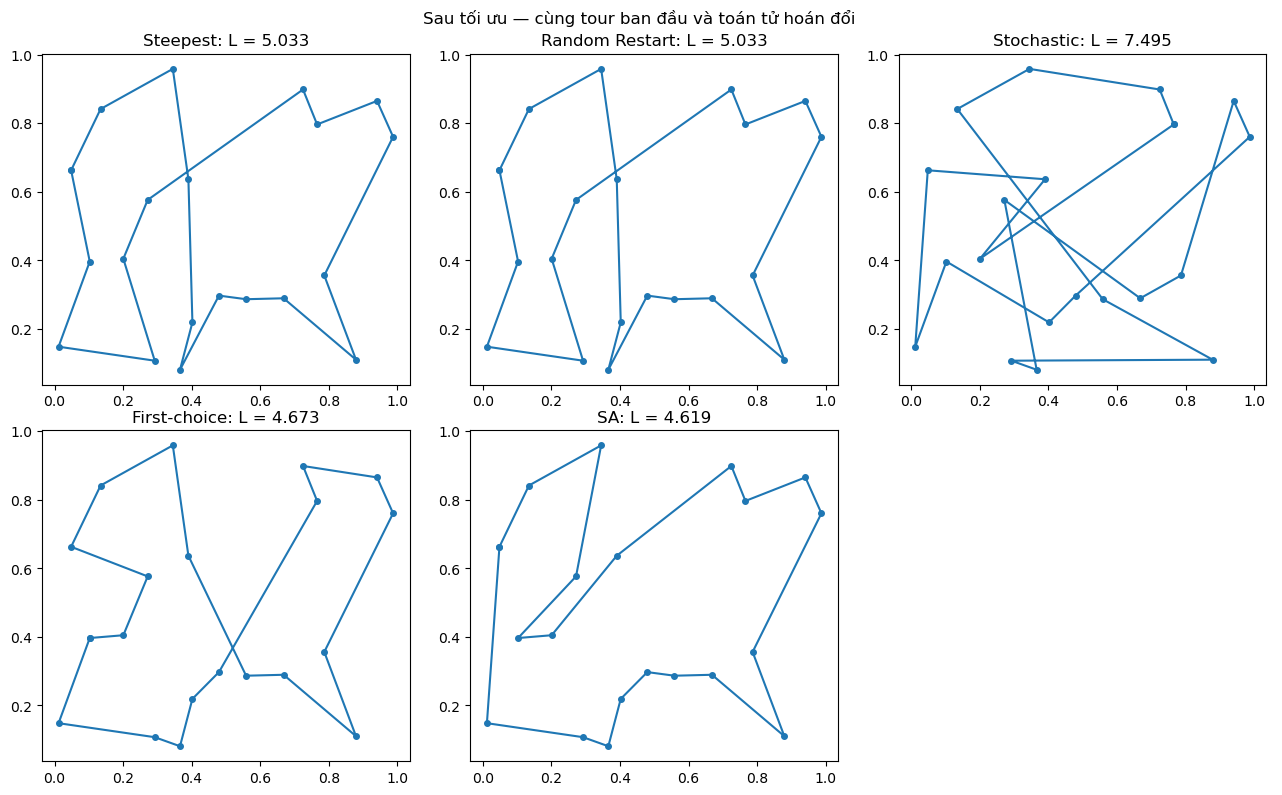

In [12]:
instance, start, runs = tsp_example
plt.figure(figsize=(6, 5))
plt.title('Trước tối ưu — cùng bộ 20 thành phố')
show_tsp(instance, start)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, run) in zip(axes.flat, runs.items()):
    route = run['tour'] + [run['tour'][0]]
    points = instance['pos'].iloc[route]
    ax.plot(points.x, points.y, 'o-', markersize=4)
    ax.set_title(f"{name}: L = {run['length']:.3f}")
    ax.set_aspect('equal', adjustable='box')
axes.flat[-1].axis('off')
fig.suptitle('Sau tối ưu — cùng tour ban đầu và toán tử hoán đổi')
fig.tight_layout()
plt.show()

In [13]:
tsp_notes = []
for n in [10, 20, 40]:
    group = tsp_summary.loc[n]
    best_name = group.tour_sau_TB.idxmin()
    fast_name = group.thoi_gian_ms_TB.idxmin()
    tsp_notes.append(f'- **n = {n}:** tour trung bình ngắn nhất là {best_name} '
                     f'({group.loc[best_name, "tour_sau_TB"]:.3f}); '
                     f'nhanh nhất là {fast_name} ({group.loc[fast_name, "thoi_gian_ms_TB"]:.2f} ms).')
display(Markdown('\n'.join(tsp_notes)))

- **n = 10:** tour trung bình ngắn nhất là Random Restart (2.821); nhanh nhất là Steepest (0.51 ms).
- **n = 20:** tour trung bình ngắn nhất là First-choice (4.346); nhanh nhất là First-choice (6.12 ms).
- **n = 40:** tour trung bình ngắn nhất là First-choice (7.466); nhanh nhất là Random Restart (12.82 ms).

**Nhận xét:** Steepest và Stochastic duyệt n(n−1)/2 hàng xóm mỗi vòng; dùng hàm `tour_length` O(n) nên một lượt duyệt lân cận tốn O(n³). First-choice và SA chỉ đánh giá một hàng xóm mỗi bước. Random Restart có thể thoát nghiệm cục bộ bằng điểm xuất phát khác, nhưng chia sẻ cùng ngân sách nên không bảo đảm luôn thắng Steepest. SA có thể đi qua bước xấu để thoát cực tiểu; lịch nhiệt đã chọn chưa được tối ưu riêng cho từng n. Khi tăng số thành phố, lân cận tăng và cùng ngân sách cho phép ít lượt duyệt đầy đủ hơn. Đối chiếu đồng thời chất lượng, thời gian và số đánh giá trong bảng.

Đã hoàn thành các phần bắt buộc của Bài 7. Genetic Algorithm là phần bonus của đề.

## Bonus: Genetic Algorithm [+1 Point]

In [14]:
# Code goes here